This is where i am importing all the library and the v2 of my model


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score,
    GridSearchCV, TunedThresholdClassifierCV,
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import mutual_info_classif, chi2, f_classif
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    recall_score, f1_score, roc_auc_score, roc_curve,
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from ml_utils import MultiMethodFeatureSelector

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully")

All libraries imported successfully


Cell 2 — Load & Explore Data

In [15]:
# Load dataset
df = pd.read_csv('data/Prostate_Cancer_v2.csv')

print(f"Dataset loaded successfully")
print(f"   Shape     : {df.shape[0]} rows × {df.shape[1]} columns")
print(f"   Columns   : {df.columns.tolist()}")
print()
print("Target Distribution (diagnosis_result):")
print(df['diagnosis_result'].value_counts())
print(df['diagnosis_result'].value_counts(normalize=True).round(3))
print()
print("🔍 Missing Values:")
print(df.isnull().sum())
print()
print("Basic Statistics:")
df.describe()


Dataset loaded successfully
   Shape     : 2000 rows × 18 columns
   Columns   : ['id', 'age', 'BMI', 'PSA_level', 'free_PSA_ratio', 'testosterone_level', 'alkaline_phosphatase', 'family_history', 'smoking_status', 'radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'symmetry', 'fractal_dimension', 'diagnosis_result']

Target Distribution (diagnosis_result):
diagnosis_result
M    1009
B     991
Name: count, dtype: int64
diagnosis_result
M    0.504
B    0.496
Name: proportion, dtype: float64

🔍 Missing Values:
id                      0
age                     0
BMI                     0
PSA_level               0
free_PSA_ratio          0
testosterone_level      0
alkaline_phosphatase    0
family_history          0
smoking_status          0
radius                  0
texture                 0
perimeter               0
area                    0
smoothness              0
compactness             0
symmetry                0
fractal_dimension       0
diagnosis_result        

,id,age,BMI,PSA_level,free_PSA_ratio,testosterone_level,alkaline_phosphatase,family_history,radius,texture,perimeter,area,smoothness,compactness,symmetry,fractal_dimension
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000
mean,1000.500000,63.135000,27.056050,11.861575,0.164015,476.194150,97.510350,0.341500,16.263500,18.177000,109.410000,878.883500,0.110374,0.183878,0.212003,0.07271
std,577.494589,11.764862,4.386766,8.338162,0.073308,158.660634,31.694599,0.474331,4.697244,4.437512,32.034247,481.420138,0.021075,0.084100,0.045579,0.01301
min,1.000000,40.000000,18.000000,0.500000,0.050000,200.000000,40.000000,0.000000,8.000000,10.000000,50.000000,152.000000,0.070000,0.040000,0.130000,0.05000
25%,500.750000,54.750000,24.100000,4.910000,0.100000,356.725000,70.400000,0.000000,13.000000,15.000000,84.000000,507.750000,0.095000,0.115000,0.176000,0.06300
50%,1000.500000,64.000000,27.300000,9.295000,0.150000,461.700000,99.200000,0.000000,16.000000,18.000000,109.000000,783.000000,0.110000,0.175000,0.211000,0.07200
75%,1500.250000,72.000000,30.300000,18.402500,0.230000,600.075000,125.600000,1.000000,20.000000,21.000000,134.000000,1245.500000,0.126000,0.250000,0.246000,0.08100
max,2000.000000,84.000000,35.000000,29.990000,0.300000,798.800000,149.900000,1.000000,25.000000,27.000000,169.000000,1899.000000,0.150000,0.350000,0.300000,0.10000


Cell 3 — Drop Irrelevant & Imaging Columns

In [16]:
imaging_cols = ['id', 'radius', 'texture', 'perimeter', 'area',
                'smoothness', 'compactness', 'symmetry', 'fractal_dimension']

df = df.drop(columns=imaging_cols)

print(f"✅ Dropped columns: {imaging_cols}")
print(f"   Remaining shape : {df.shape}")
print(f"   Remaining columns: {df.columns.tolist()}")

✅ Dropped columns: ['id', 'radius', 'texture', 'perimeter', 'area', 'smoothness', 'compactness', 'symmetry', 'fractal_dimension']
   Remaining shape : (2000, 9)
   Remaining columns: ['age', 'BMI', 'PSA_level', 'free_PSA_ratio', 'testosterone_level', 'alkaline_phosphatase', 'family_history', 'smoking_status', 'diagnosis_result']


Cell 4 — Encode Target & Categorical Features

In [17]:
df['diagnosis_result'] = df['diagnosis_result'].map({'M': 1, 'B': 0})

df['smoking_status'] = df['smoking_status'].map({
    'Never': 0, 'Former': 1, 'Current': 2
})

print("✅ Encoding complete")
print(f"   Target distribution: {df['diagnosis_result'].value_counts().to_dict()}")
print(f"   Smoking status encoded: {df['smoking_status'].unique()}")
print()
print(df.head())

✅ Encoding complete
   Target distribution: {1: 1009, 0: 991}
   Smoking status encoded: [0 1 2]

   age   BMI  PSA_level  free_PSA_ratio  testosterone_level  \
0   66  27.5      27.94            0.07               281.6   
1   66  22.2       9.05            0.15               665.5   
2   44  24.8       4.91            0.30               643.4   
3   46  26.5       5.66            0.16               583.3   
4   69  34.8      25.47            0.10               301.9   

   alkaline_phosphatase  family_history  smoking_status  diagnosis_result  
0                 138.0               1               0                 1  
1                  97.8               1               0                 1  
2                  61.0               0               1                 1  
3                  69.1               0               0                 0  
4                 143.6               0               2                 0  


Cell 5 — Train / Test Split

In [18]:
X = df.drop(columns=['diagnosis_result'])
y = df['diagnosis_result']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"✅ Split complete")
print(f"   Train : {len(X_train)} samples  |  Test : {len(X_test)} samples")
print(f"   Train cancer rate : {y_train.mean():.2%}")
print(f"   Test  cancer rate : {y_test.mean():.2%}")
print()
print("Feature selection, scaling, and SMOTE now live INSIDE the pipeline,")
print("so they are refit per-CV-fold on training data only.")

✅ Split complete
   Train : 1600 samples  |  Test : 400 samples
   Train cancer rate : 50.44%
   Test  cancer rate : 50.50%

Feature selection, scaling, and SMOTE now live INSIDE the pipeline,
so they are refit per-CV-fold on training data only.


Cell 6 — Custom Feature Selector (Pipeline-safe)

In [19]:
def build_pipeline(clf):
    """Selector -> Scaler -> SMOTE -> Classifier, all CV-safe."""
    return Pipeline([
        ('selector', MultiMethodFeatureSelector(k=6)),
        ('scaler', MinMaxScaler()),
        ('smote', SMOTE(random_state=42)),
        ('clf', clf),
    ])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("✅ Feature selector + pipeline factory ready")

✅ Feature selector + pipeline factory ready


Cell 7 — Logistic Regression (Pipeline + Threshold Tuning)

MODEL 1 — LOGISTIC REGRESSION

🔁 5-Fold CV ROC-AUC (pipeline): 0.6807 ± 0.0193
   Individual folds  : [np.float64(0.6958), np.float64(0.7095), np.float64(0.6558), np.float64(0.6719), np.float64(0.6705)]

📌 Top 6 Selected Features:
1. PSA_level
2. alkaline_phosphatase
3. testosterone_level
4. free_PSA_ratio
5. age
6. BMI

🎯 Tuned decision threshold : 0.4905  (default is 0.5000)

📊 LR — Test Performance:
   Accuracy             : 0.7225
   Recall (Sensitivity) : 0.7129  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.7218
   ROC-AUC              : 0.7175

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.71      0.73      0.72       198
   Malignant       0.73      0.71      0.72       202

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      0.72       400



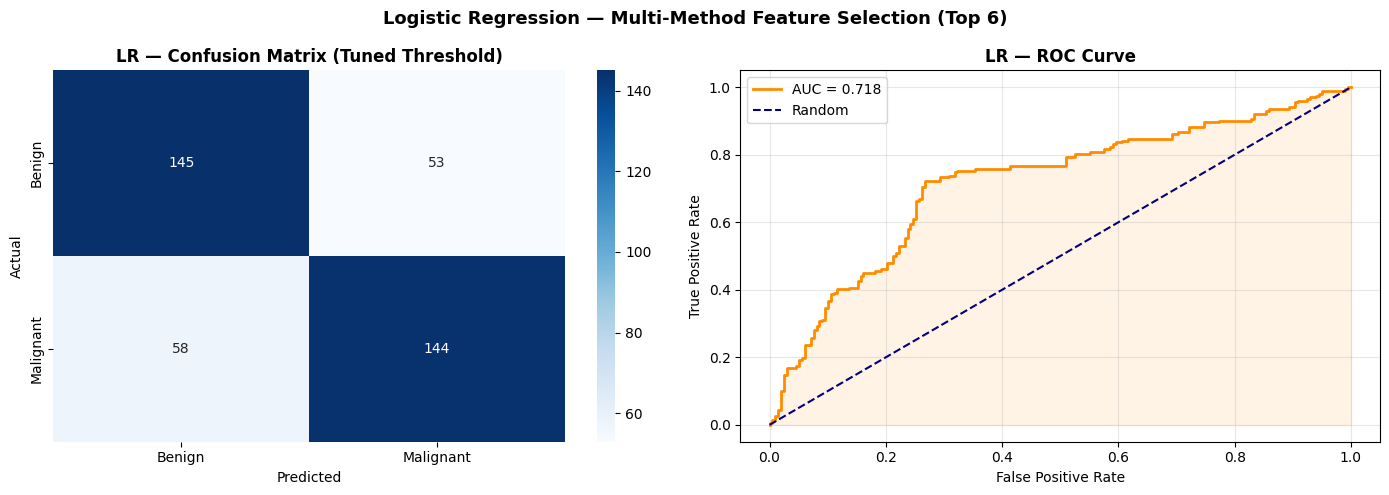

LR complete


In [20]:
print("=" * 60)
print("MODEL 1 — LOGISTIC REGRESSION")
print("=" * 60)

lr_pipeline = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))

cv_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"\n🔁 5-Fold CV ROC-AUC (pipeline): {cv_lr.mean():.4f} ± {cv_lr.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_lr]}")

lr_tuned = TunedThresholdClassifierCV(
    lr_pipeline, scoring='f1', cv=cv, store_cv_results=True,
)
lr_tuned.fit(X_train, y_train)

lr_pipeline.fit(X_train, y_train)
selector = lr_pipeline.named_steps['selector']

print("\n📌 Top 6 Selected Features:")
for i, feature in enumerate(selector.top_features_, start=1):
    print(f"{i}. {feature}")

print(f"\n🎯 Tuned decision threshold : {lr_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_lr = lr_tuned.predict(X_test)
y_prob_lr = lr_tuned.predict_proba(X_test)[:, 1]

acc_lr = accuracy_score(y_test, y_pred_lr)
rec_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print(f"\n📊 LR — Test Performance:")
print(f"   Accuracy             : {acc_lr:.4f}")
print(f"   Recall (Sensitivity) : {rec_lr:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_lr:.4f}")
print(f"   ROC-AUC              : {roc_auc_lr:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Benign', 'Malignant']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues',
            ax=axes[0], xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[0].set_title('LR — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
axes[1].plot(fpr_lr, tpr_lr, color='darkorange', lw=2, label=f'AUC = {roc_auc_lr:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_lr, tpr_lr, alpha=0.1, color='darkorange')
axes[1].set_title('LR — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle(
    'Logistic Regression — Multi-Method Feature Selection (Top 6)',
    fontsize=13,
    fontweight='bold'
)
plt.tight_layout()
plt.savefig('prostate_lr_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("LR complete")

Cell 8 — KNN (GridSearchCV for K + Threshold Tuning)

MODEL 2 — K-NEAREST NEIGHBORS (KNN)

🔍 Finding optimal K via GridSearchCV (scoring = F1)...
   ✅ Best K : 27  (CV F1 : 0.6897)
   5-Fold CV ROC-AUC : 0.6816 ± 0.0248
   Individual folds  : [np.float64(0.7), np.float64(0.7187), np.float64(0.6779), np.float64(0.6536), np.float64(0.658)]

🎯 Tuned decision threshold : 0.4961  (default is 0.5000)

📊 KNN — Test Performance:
   Accuracy             : 0.7175
   Recall (Sensitivity) : 0.7228  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.7210
   ROC-AUC              : 0.7257

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.72      0.71      0.71       198
   Malignant       0.72      0.72      0.72       202

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weighted avg       0.72      0.72      0.72       400



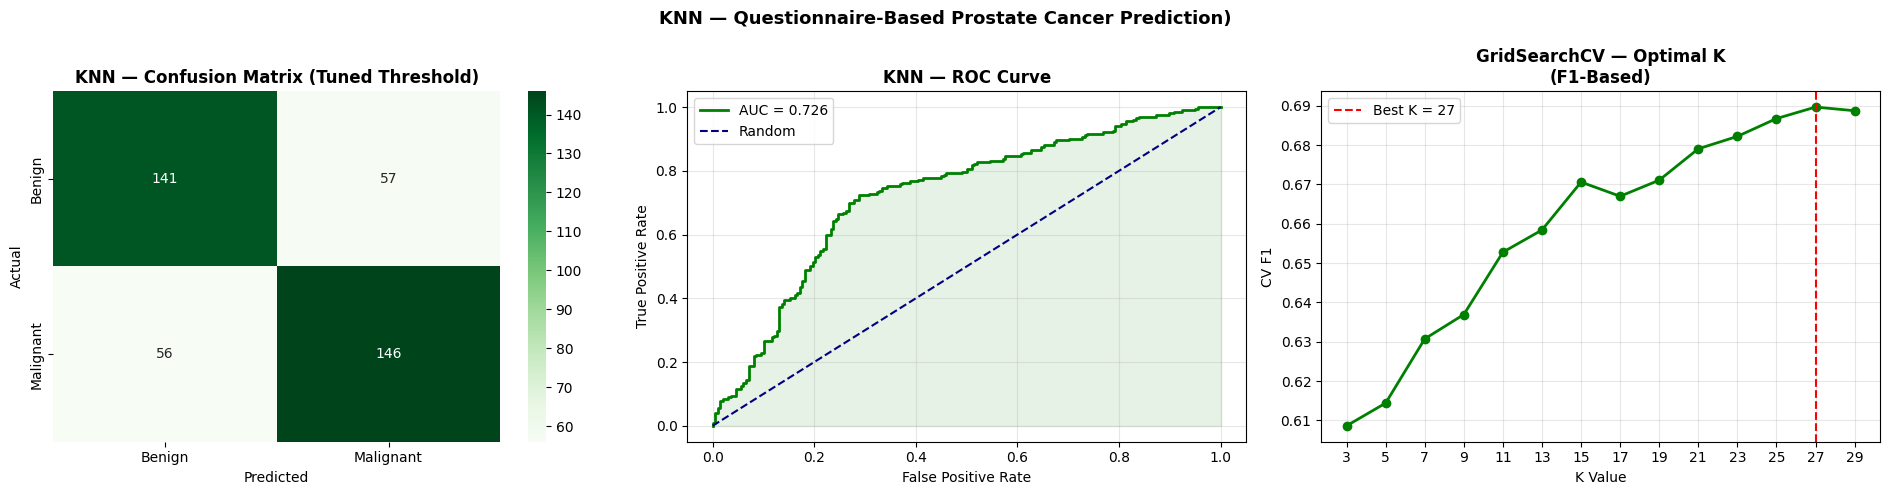

✅ KNN complete


In [21]:
print("=" * 60)
print("MODEL 2 — K-NEAREST NEIGHBORS (KNN)")
print("=" * 60)

knn_pipeline = build_pipeline(KNeighborsClassifier(weights='distance'))
param_grid_knn = {'clf__n_neighbors': list(range(3, 31, 2))}  # odd numbers from 3 to 29

print("\n🔍 Finding optimal K via GridSearchCV (scoring = F1)...")
knn_grid = GridSearchCV(knn_pipeline, param_grid_knn, scoring='f1', cv=cv, n_jobs=-1)
knn_grid.fit(X_train, y_train)

best_k = knn_grid.best_params_['clf__n_neighbors']
print(f"   ✅ Best K : {best_k}  (CV F1 : {knn_grid.best_score_:.4f})")

cv_knn = cross_val_score(knn_grid.best_estimator_, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_knn.mean():.4f} ± {cv_knn.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_knn]}")

knn_tuned = TunedThresholdClassifierCV(
    knn_grid.best_estimator_, scoring='f1', cv=cv, store_cv_results=True,
)
knn_tuned.fit(X_train, y_train)
print(f"\n🎯 Tuned decision threshold : {knn_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_knn = knn_tuned.predict(X_test)
y_prob_knn = knn_tuned.predict_proba(X_test)[:, 1]

acc_knn = accuracy_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)
roc_auc_knn = roc_auc_score(y_test, y_prob_knn)

print(f"\n📊 KNN — Test Performance:")
print(f"   Accuracy             : {acc_knn:.4f}")
print(f"   Recall (Sensitivity) : {rec_knn:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_knn:.4f}")
print(f"   ROC-AUC              : {roc_auc_knn:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_knn, target_names=['Benign', 'Malignant']))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens',
            ax=axes[0], xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[0].set_title('KNN — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
axes[1].plot(fpr_knn, tpr_knn, color='green', lw=2, label=f'AUC = {roc_auc_knn:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_knn, tpr_knn, alpha=0.1, color='green')
axes[1].set_title('KNN — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

k_range = param_grid_knn['clf__n_neighbors']
knn_cv_results = knn_grid.cv_results_['mean_test_score']
axes[2].plot(k_range, knn_cv_results, marker='o', color='green', lw=2)
axes[2].axvline(best_k, color='red', linestyle='--', label=f'Best K = {best_k}')
axes[2].set_title('GridSearchCV — Optimal K\n(F1-Based)', fontweight='bold')
axes[2].set_xlabel('K Value'); axes[2].set_ylabel('CV F1')
axes[2].set_xticks(k_range); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('KNN — Questionnaire-Based Prostate Cancer Prediction)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('prostate_knn_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ KNN complete")

Cell 9 — SVM (GridSearchCV for C + Threshold Tuning)

MODEL 3 — SUPPORT VECTOR MACHINE (SVM)

🔍 Finding optimal C via GridSearchCV (scoring = F1)...
   C = 0.1   → CV F1 : 0.6936
   C = 0.5   → CV F1 : 0.6936
   C = 1.0   → CV F1 : 0.6936
   C = 5.0   → CV F1 : 0.6936
   C = 10.0  → CV F1 : 0.6936

   ✅ Best C : 0.1  (CV F1 : 0.6936)
   5-Fold CV ROC-AUC : 0.6763 ± 0.0339
   Individual folds  : [np.float64(0.7057), np.float64(0.7232), np.float64(0.6622), np.float64(0.6288), np.float64(0.6617)]

🎯 Tuned decision threshold : 0.4270  (default is 0.5000)

📊 SVM — Test Performance:
   Accuracy             : 0.7225
   Recall (Sensitivity) : 0.7129  ← CRITICAL FOR CANCER SCREENING
   F1-Score             : 0.7218
   ROC-AUC              : 0.7268

   Classification Report:
              precision    recall  f1-score   support

      Benign       0.71      0.73      0.72       198
   Malignant       0.73      0.71      0.72       202

    accuracy                           0.72       400
   macro avg       0.72      0.72      0.72       400
weight

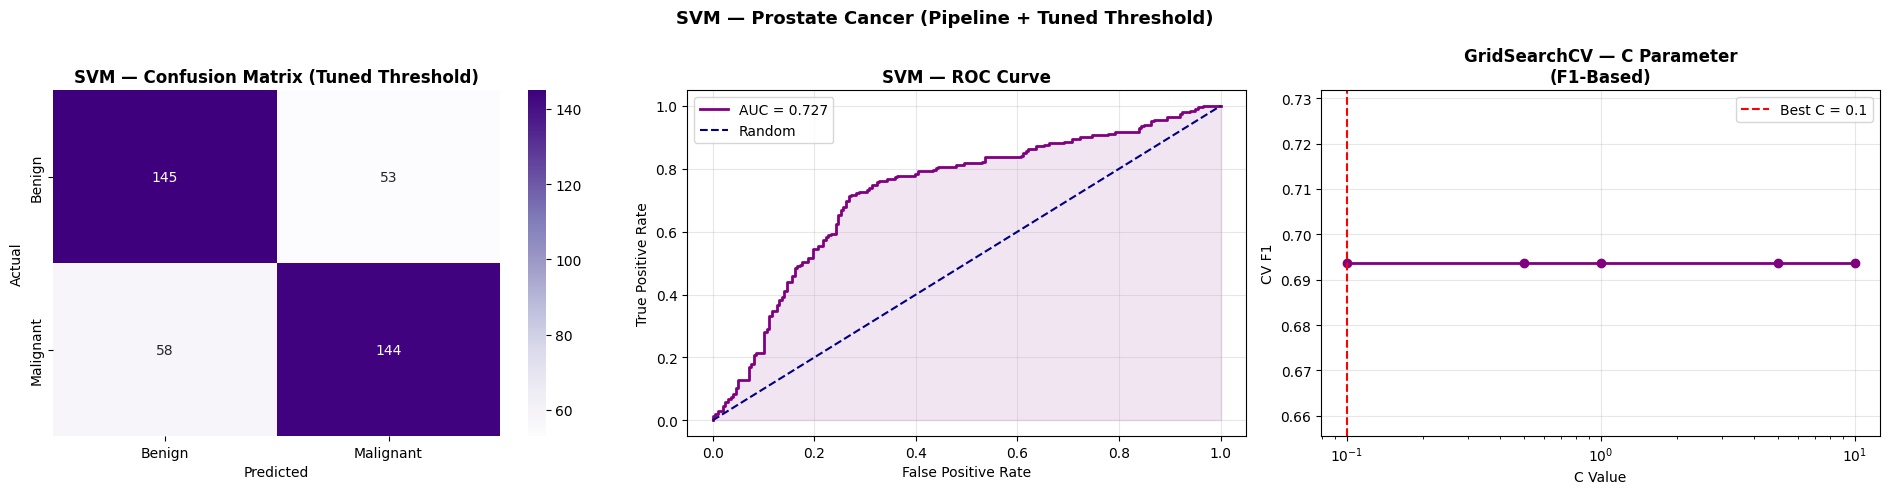

✅ SVM complete


In [22]:
print("=" * 60)
print("MODEL 3 — SUPPORT VECTOR MACHINE (SVM)")
print("=" * 60)

svm_pipeline = build_pipeline(SVC(kernel='rbf', gamma='scale', probability=True, random_state=42))
param_grid_svm = {'clf__C': [0.1, 0.5, 1.0, 5.0, 10.0]}

print("\n🔍 Finding optimal C via GridSearchCV (scoring = F1)...")
svm_grid = GridSearchCV(svm_pipeline, param_grid_svm, scoring='f1', cv=cv, n_jobs=-1)
svm_grid.fit(X_train, y_train)

for c, score in zip(param_grid_svm['clf__C'], svm_grid.cv_results_['mean_test_score']):
    print(f"   C = {c:<5} → CV F1 : {score:.4f}")

best_c = svm_grid.best_params_['clf__C']
print(f"\n   ✅ Best C : {best_c}  (CV F1 : {svm_grid.best_score_:.4f})")

cv_svm = cross_val_score(svm_grid.best_estimator_, X_train, y_train, cv=cv, scoring='roc_auc')
print(f"   5-Fold CV ROC-AUC : {cv_svm.mean():.4f} ± {cv_svm.std():.4f}")
print(f"   Individual folds  : {[round(s, 4) for s in cv_svm]}")

svm_tuned = TunedThresholdClassifierCV(
    svm_grid.best_estimator_, scoring='f1', cv=cv, store_cv_results=True,
)
svm_tuned.fit(X_train, y_train)
print(f"\n🎯 Tuned decision threshold : {svm_tuned.best_threshold_:.4f}  (default is 0.5000)")

y_pred_svm = svm_tuned.predict(X_test)
y_prob_svm = svm_tuned.predict_proba(X_test)[:, 1]

acc_svm = accuracy_score(y_test, y_pred_svm)
rec_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)
roc_auc_svm = roc_auc_score(y_test, y_prob_svm)

print(f"\n📊 SVM — Test Performance:")
print(f"   Accuracy             : {acc_svm:.4f}")
print(f"   Recall (Sensitivity) : {rec_svm:.4f}  ← CRITICAL FOR CANCER SCREENING")
print(f"   F1-Score             : {f1_svm:.4f}")
print(f"   ROC-AUC              : {roc_auc_svm:.4f}")
print(f"\n   Classification Report:")
print(classification_report(y_test, y_pred_svm, target_names=['Benign', 'Malignant']))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(confusion_matrix(y_test, y_pred_svm), annot=True, fmt='d', cmap='Purples',
            ax=axes[0], xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
axes[0].set_title('SVM — Confusion Matrix (Tuned Threshold)', fontweight='bold')
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual')

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
axes[1].plot(fpr_svm, tpr_svm, color='purple', lw=2, label=f'AUC = {roc_auc_svm:.3f}')
axes[1].plot([0, 1], [0, 1], 'navy', lw=1.5, linestyle='--', label='Random')
axes[1].fill_between(fpr_svm, tpr_svm, alpha=0.1, color='purple')
axes[1].set_title('SVM — ROC Curve', fontweight='bold')
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].legend(); axes[1].grid(alpha=0.3)

c_values = param_grid_svm['clf__C']
svm_cv_results = svm_grid.cv_results_['mean_test_score']
axes[2].plot(c_values, svm_cv_results, marker='o', color='purple', lw=2)
axes[2].axvline(best_c, color='red', linestyle='--', label=f'Best C = {best_c}')
axes[2].set_title('GridSearchCV — C Parameter\n(F1-Based)', fontweight='bold')
axes[2].set_xlabel('C Value'); axes[2].set_ylabel('CV F1')
axes[2].set_xscale('log'); axes[2].legend(); axes[2].grid(alpha=0.3)

plt.suptitle('SVM — Prostate Cancer (Pipeline + Tuned Threshold)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('prostate_svm_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ SVM complete")

Import Joblib

In [24]:
import os, joblib
save_path = 'models/prostate_cancer_lr_model.pkl'
os.makedirs('models', exist_ok=True)
joblib.dump(lr_tuned, save_path)
print("✅ Prostate model saved to:", os.path.abspath(save_path))

✅ Prostate model saved to: c:\Users\user\Desktop\cancer_prediction_model_v2\models\prostate_cancer_lr_model.pkl
